# Exercise: missing data  

Save the file `propertydata.csv` in the folder **sample_data** and load `propertydata.csv` into a pandas dataframe 




In [1]:
import pandas as pd
propertydata = pd.read_csv("sample_data/propertydata.csv")
print(propertydata)

         PID  ST_NUM     ST_NAME OWN_OCCUPIED NUM_BEDROOMS NUM_BATH SQ_FT
0  100001000   104.0      PUTNAM            Y            3        1  1000
1  100002000   197.0   LEXINGTON            N            3      1.5    --
2  100003000     NaN   LEXINGTON            N          NaN        1   850
3  100004000   201.0    BERKELEY           12            1      NaN   700
4  100005000   203.0    BERKELEY            Y            3        2  1600
5  100006000   207.0    BERKELEY            Y          NaN        1   800
6  100007000     NaN  WASHINGTON          NaN            2   HURLEY   950
7  100008000   213.0     TREMONT            Y            1        1   NaN
8  100009000   215.0     TREMONT            Y           na        2  1800


Manually review the data



In [2]:
print(propertydata)

         PID  ST_NUM     ST_NAME OWN_OCCUPIED NUM_BEDROOMS NUM_BATH SQ_FT
0  100001000   104.0      PUTNAM            Y            3        1  1000
1  100002000   197.0   LEXINGTON            N            3      1.5    --
2  100003000     NaN   LEXINGTON            N          NaN        1   850
3  100004000   201.0    BERKELEY           12            1      NaN   700
4  100005000   203.0    BERKELEY            Y            3        2  1600
5  100006000   207.0    BERKELEY            Y          NaN        1   800
6  100007000     NaN  WASHINGTON          NaN            2   HURLEY   950
7  100008000   213.0     TREMONT            Y            1        1   NaN
8  100009000   215.0     TREMONT            Y           na        2  1800


Try the missing data visualization module **missingno** (https://github.com/ResidentMario/missingno)



*   Matrix
*   Bar Chart



Ellipsis

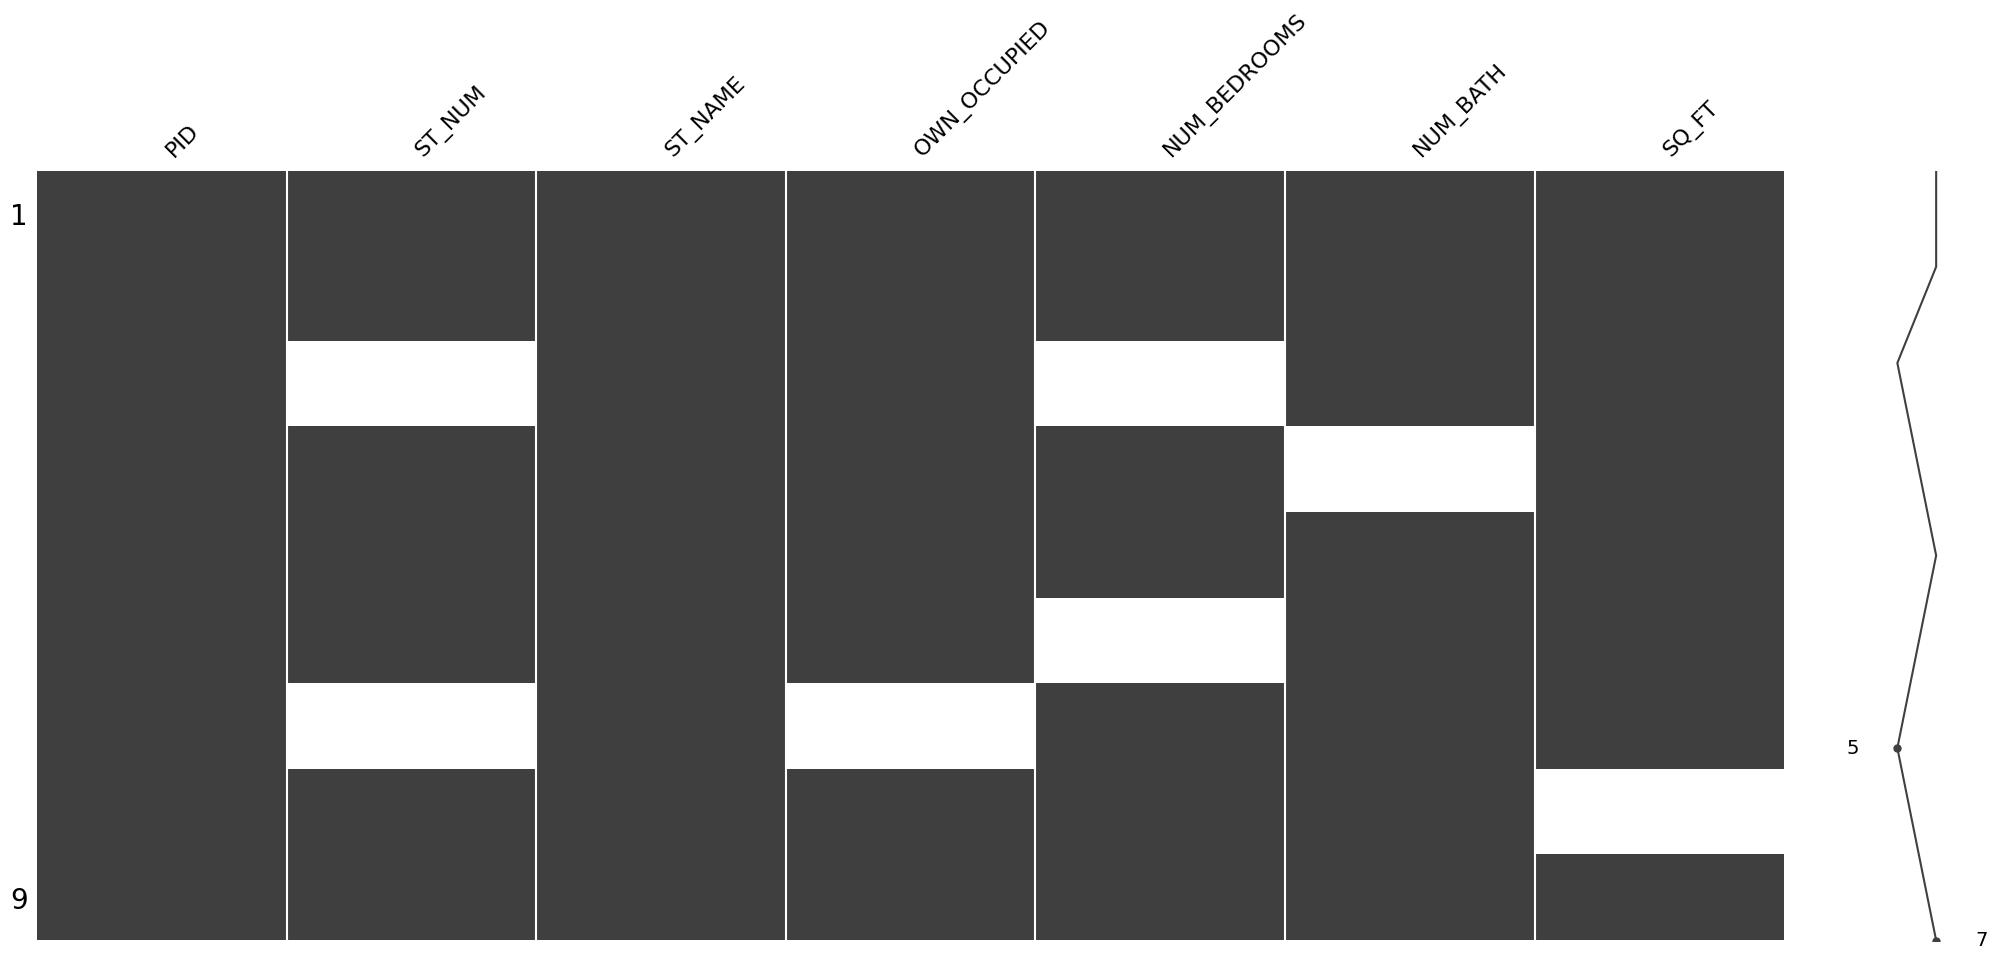

In [4]:
import missingno as msno
import matplotlib as plt
property = pd.read_csv("sample_data/propertydata.csv")
msno.matrix(property)



...

Fix the missing data of each column:
1. Insert NaN for all missing or wrong values.
2. Use appropriate methods for fixing the missing data.

In [6]:
import pandas as pd
import numpy as np

# 1.)
# print(f'Before exchanging invalid values:\n{property}\n')

sanitized_property = pd.read_csv(
    'sample_data/propertydata.csv',
    na_values=['--', 'na', 'HURLEY']
)

# print(f'Sanitized the data:\n{sanitized_property}')

sanitized_property['OWN_OCCUPIED'] = sanitized_property['OWN_OCCUPIED'].replace('12', np.nan)

print(f'Cleaned data:\n{sanitized_property}')





Cleaned data:
         PID  ST_NUM     ST_NAME OWN_OCCUPIED  NUM_BEDROOMS  NUM_BATH   SQ_FT
0  100001000   104.0      PUTNAM            Y           3.0       1.0  1000.0
1  100002000   197.0   LEXINGTON            N           3.0       1.5     NaN
2  100003000     NaN   LEXINGTON            N           NaN       1.0   850.0
3  100004000   201.0    BERKELEY          NaN           1.0       NaN   700.0
4  100005000   203.0    BERKELEY            Y           3.0       2.0  1600.0
5  100006000   207.0    BERKELEY            Y           NaN       1.0   800.0
6  100007000     NaN  WASHINGTON          NaN           2.0       NaN   950.0
7  100008000   213.0     TREMONT            Y           1.0       1.0     NaN
8  100009000   215.0     TREMONT            Y           NaN       2.0  1800.0


In [7]:
import numpy as np

# 2.) Missing values

# SQ_FT: Replace missing values with the mean
sanitized_property['SQ_FT'] = sanitized_property['SQ_FT'].fillna(
    sanitized_property['SQ_FT'].mean()
)

# NUM_BATH: Round down all values
sanitized_property['NUM_BATH'] = np.floor(
    sanitized_property['NUM_BATH']
)

# NUM_BATH: Replace missing values with the mean and round down
sanitized_property['NUM_BATH'] = sanitized_property['NUM_BATH'].fillna(
    np.floor(sanitized_property['NUM_BATH'].mean())
)

# NUM_BATH: Convert to integer
sanitized_property['NUM_BATH'] = sanitized_property['NUM_BATH'].astype(int)


# NUM_BEDROOMS: Replace missing values with the mean
sanitized_property['NUM_BEDROOMS'] = sanitized_property['NUM_BEDROOMS'].fillna(
    sanitized_property['NUM_BEDROOMS'].mean()
)

# NUM_BEDROOMS: Round down all values and convert to integer
sanitized_property['NUM_BEDROOMS'] = np.floor(
    sanitized_property['NUM_BEDROOMS']
).astype(int)


# ST_NUM: Replace missing values with the mean
sanitized_property['ST_NUM'] = sanitized_property['ST_NUM'].fillna(
    sanitized_property['ST_NUM'].mean()
)

# ST_NUM: Round down all values and convert to integer
sanitized_property['ST_NUM'] = np.floor(
    sanitized_property['ST_NUM']
).astype(int)

print(f'Cleaned data:\n{sanitized_property}')

Cleaned data:
         PID  ST_NUM     ST_NAME OWN_OCCUPIED  NUM_BEDROOMS  NUM_BATH   SQ_FT
0  100001000     104      PUTNAM            Y             3         1  1000.0
1  100002000     197   LEXINGTON            N             3         1  1100.0
2  100003000     191   LEXINGTON            N             2         1   850.0
3  100004000     201    BERKELEY          NaN             1         1   700.0
4  100005000     203    BERKELEY            Y             3         2  1600.0
5  100006000     207    BERKELEY            Y             2         1   800.0
6  100007000     191  WASHINGTON          NaN             2         1   950.0
7  100008000     213     TREMONT            Y             1         1  1100.0
8  100009000     215     TREMONT            Y             2         2  1800.0


Split the frame into 2 subframes by eliminating the non NAN lines within the OWN_OCCUPIED column

In [8]:
# 3.) Split dataset

property_features = sanitized_property.drop(columns=['OWN_OCCUPIED'])
property_ownership = sanitized_property[['PID', 'OWN_OCCUPIED']]
property_ownership = property_ownership.dropna()

print(f'Property Features:\n{property_features}\n')
print(f'Property Ownership:\n{property_ownership}')

Property Features:
         PID  ST_NUM     ST_NAME  NUM_BEDROOMS  NUM_BATH   SQ_FT
0  100001000     104      PUTNAM             3         1  1000.0
1  100002000     197   LEXINGTON             3         1  1100.0
2  100003000     191   LEXINGTON             2         1   850.0
3  100004000     201    BERKELEY             1         1   700.0
4  100005000     203    BERKELEY             3         2  1600.0
5  100006000     207    BERKELEY             2         1   800.0
6  100007000     191  WASHINGTON             2         1   950.0
7  100008000     213     TREMONT             1         1  1100.0
8  100009000     215     TREMONT             2         2  1800.0

Property Ownership:
         PID OWN_OCCUPIED
0  100001000            Y
1  100002000            N
2  100003000            N
4  100005000            Y
5  100006000            Y
7  100008000            Y
8  100009000            Y


Again use the data visualization of **missingno**

<Axes: >

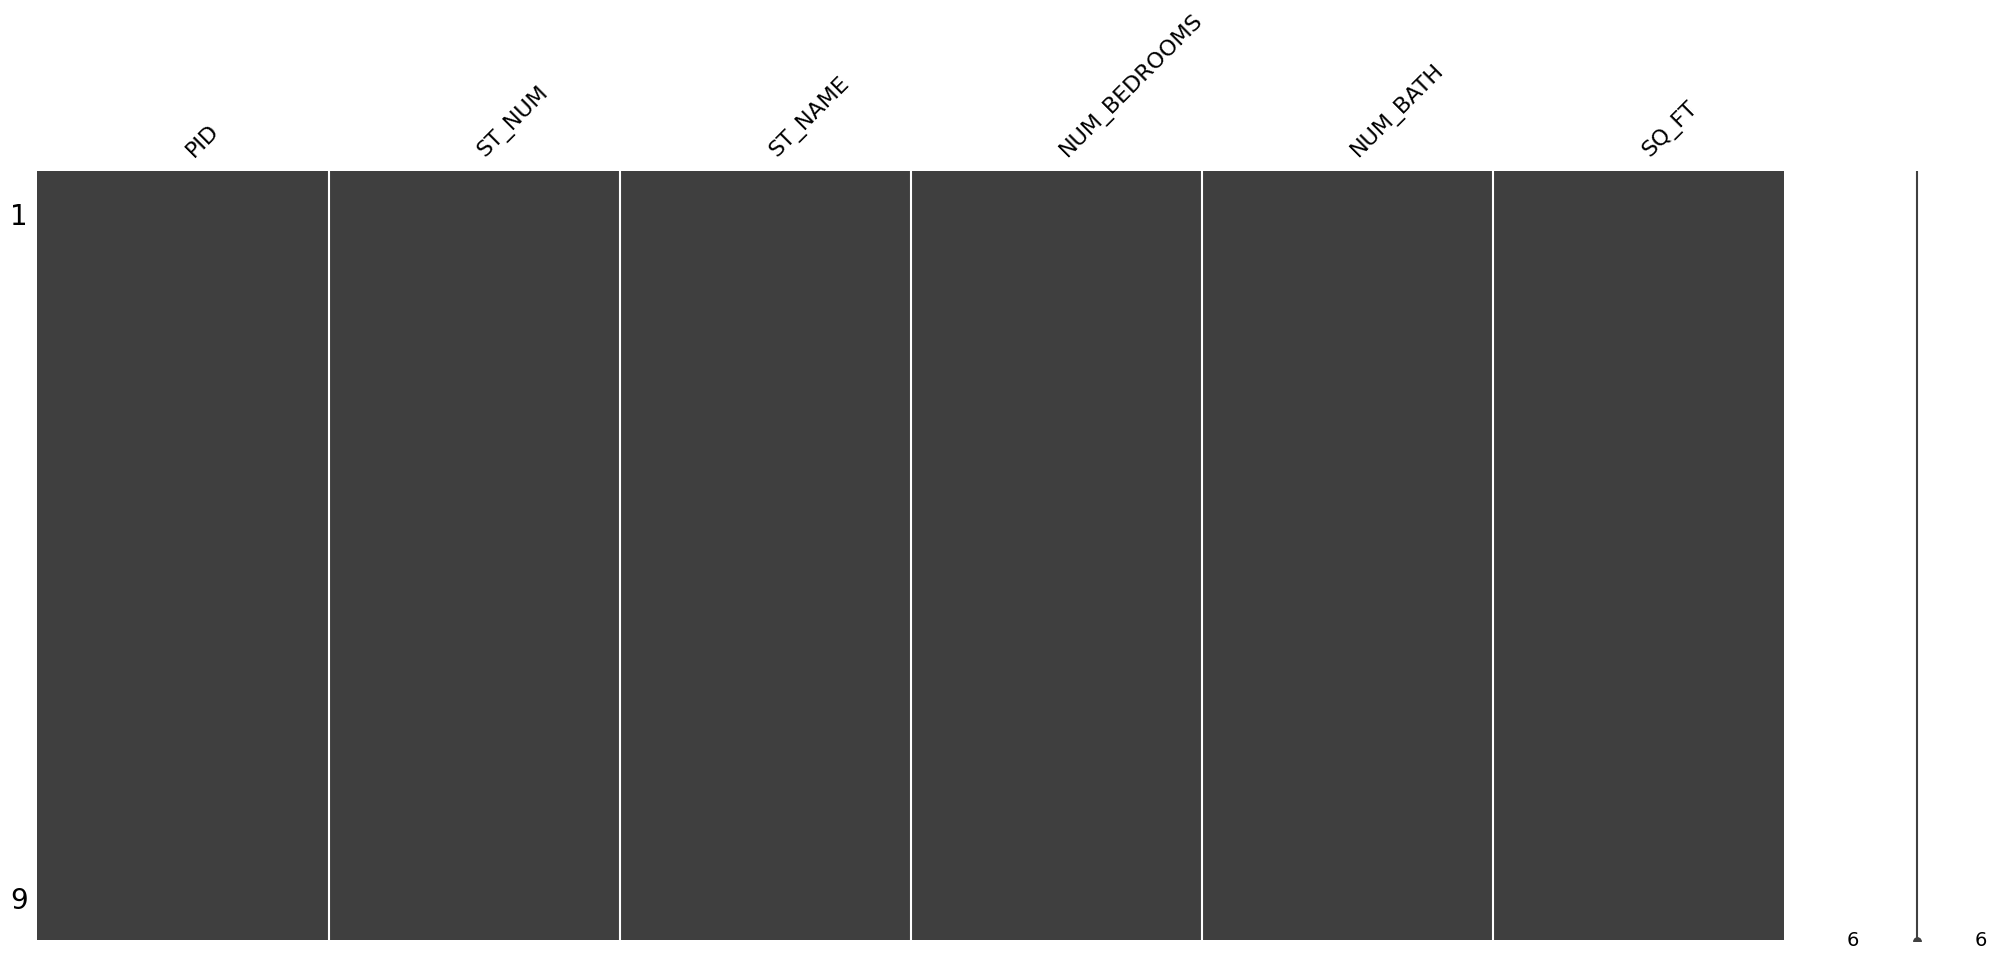

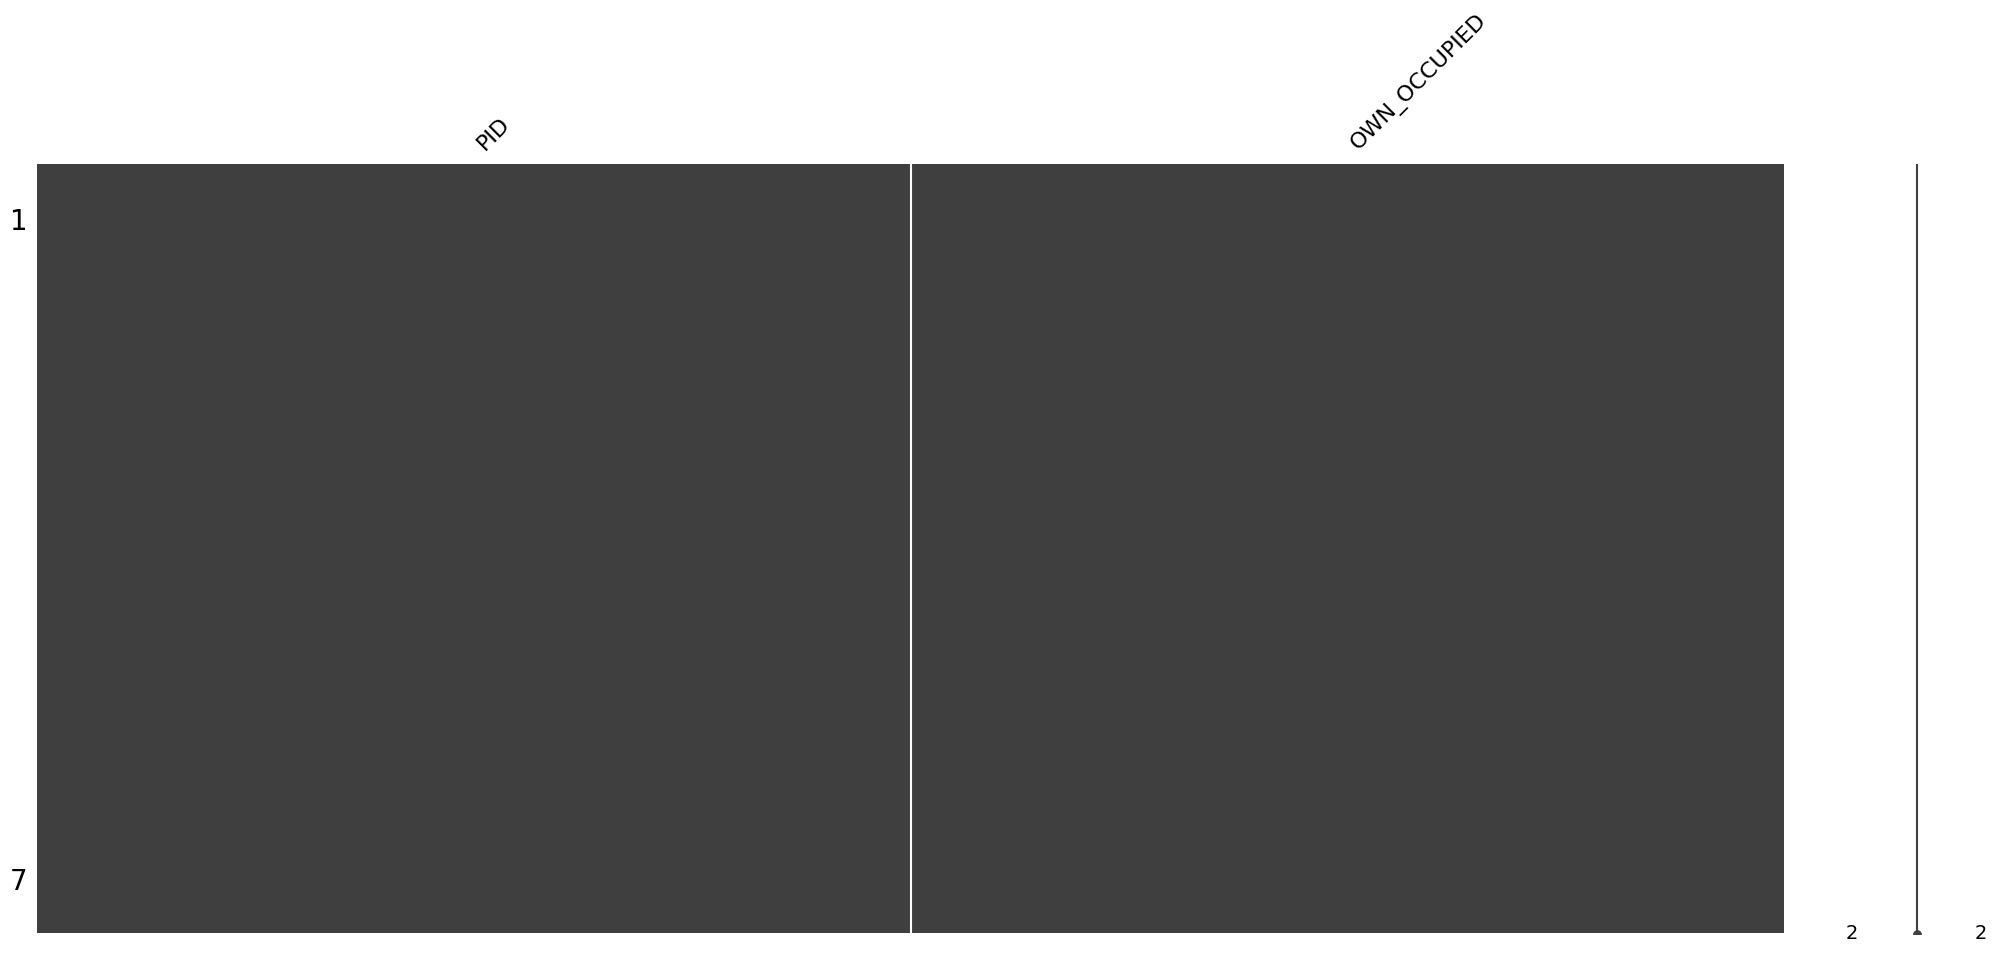

In [10]:
msno.matrix(property_features)
msno.matrix(property_ownership)
